# Исследование Высоцкого городского поселения (Ленинградская область) с помощью BlocksNet

Ноутбук шаг за шагом собирает информационную модель территории по открытым данным и считает
набор городских показателей библиотекой **BlocksNet 1.0.0a9**.

**Территория исследования:** Высоцкое городское поселение, Выборгский район, Ленинградская
область — целиком (в него входит и сам г. Высоцк, и прилегающие земли). Границы берутся
из OpenStreetMap как есть, без буфера вокруг поселения (OSM relation `2431317`).

Из кварталов заранее исключаются две вещи, которые иначе дробят территорию:

- **акватория Финского залива** внутри границ поселения (определяется по линии берега OSM);
- **полоса отвода железной дороги**: портовые пути в OSM нарисованы десятком параллельных
  веток, поэтому они объединяются в одну полосу, а не режут территорию на узкие полоски.

**Источники данных:**

| Данные | Источник | Способ |
|---|---|---|
| границы, дороги, железные дороги, вода, линия берега | OpenStreetMap | библиотека `osmnx` |
| функциональные зоны (землепользование) | OpenStreetMap | библиотека `osmnx` |
| здания (площади, этажность, население) | OpenStreetMap | `osmnx` + дозаполнение в BlocksNet |
| сервисы (школа, аптека, магазин и т.д.) | OpenStreetMap | `osmnx` + дозаполнение в BlocksNet |
| граф улиц для времени в пути | OpenStreetMap | библиотека **IduEdu** (входит в BlocksNet) |

Данные OpenStreetMap скачиваются через публичные серверы Overpass API: ноутбук сам перебирает
зеркала (список `OVERPASS_SERVERS` в ячейке 1.1), а перед скачиванием проверяет, какие из них
отвечают.

Граф для расчёта времени в пути скачивается **готовым** из OpenStreetMap отдельно для двух режимов
передвижения: **пешком** (`walk`) и **на автомобиле** (`drive`). Интермодальный граф не строится.
Время в пути везде показано **в минутах**.

**Порядок работы:** ячейки запускаются строго сверху вниз. Через несколько шагов есть
**СТОП-ТОЧКА** — там нужно остановиться и обсудить список метрик. Всё посчитанное
сохраняется в файлы в папке `data/`, поэтому при повторном запуске скачивание и расчёты
не повторяются.

## Как запускать ноутбук (Windows)

Открыть терминал PowerShell в папке репозитория и выполнить:

```powershell
cd C:\Users\harlekiro\python-package-boilerplate
.\.venv\Scripts\python.exe -m pip install -e ".[dev]"
.\.venv\Scripts\python.exe -m jupyter lab examples\vysotsk\vysotsk_study.ipynb
```

В самом ноутбуке выбирать ядро (kernel) из окружения `.venv`.
Первые ячейки, которые качают данные, требуют интернета.

**Важно:** ячейки зависят друг от друга и запускаются строго сверху вниз. Проще всего один раз нажать
`Run All Cells` (в JupyterLab — меню `Run -> Run All Cells`, в VS Code — «Run All»).
Если запустить ячейку из середины, раздел остановится с понятным сообщением
«Не выполнены ячейки выше» — просто вернитесь к началу и запустите ячейки подряд.

**Если файл ноутбука обновился (например, его поправили), а он был открыт**, в окне Jupyter может
остаться старая копия. Тогда выполняется старый код, и ошибки повторяются. Что сделать:

1. Закрыть вкладку ноутбука **без сохранения** (в JupyterLab: правой кнопкой по вкладке ->
   `Close Without Saving`; в VS Code: закрыть вкладку и на вопрос о сохранении ответить «не сохранять»).
2. Открыть файл заново (двойной щелчок по `vysotsk_study.ipynb` в списке файлов слева).
3. В меню выбрать `Kernel -> Restart Kernel` (перезапустить ядро).
4. Запустить ячейки сверху вниз.

Признак того, что открыта свежая копия: в выводе первой ячейки настроек печатается строка
`Версия ноутбука: 7`. Если такой строки нет — открыта старая копия, повторите шаги 1–3.

## 0. Проверка окружения

Ничего не скачиваем и не считаем — просто убеждаемся, что библиотеки на месте.

In [1]:
import sys
from importlib.metadata import version

for package in ["blocksnet", "iduedu", "osmnx", "geopandas", "pandas", "matplotlib", "folium", "mapclassify"]:
    print(f"{package:12s} {version(package)}")
print("Python      ", sys.version.split()[0])

blocksnet    1.0.0a9
iduedu       0.4.1
osmnx        2.1.1
geopandas    1.2.0
pandas       2.3.3
matplotlib   3.11.2
folium       0.14.0
mapclassify  2.6.1
Python       3.12.10


## 1. Настройки

Всё, что может понадобиться менять, собрано в двух ячейках ниже.

In [2]:
# --------------------------------------------------------------------------------------------------
# 1.1. Основные настройки исследования. Менять здесь.
# --------------------------------------------------------------------------------------------------

NOTEBOOK_VERSION = "8"   # версия файла ноутбука. Печатается ниже: если этого числа нет в выводе,
                         # значит запущена старая копия файла (закройте вкладку и откройте заново)

FORCE_RECOMPUTE = False   # False -> использовать уже сохранённые файлы из data/ (быстро, без повторных скачиваний)
                          # True  -> пересчитать и перекачать всё заново

TERRITORY_NAME = "Высоцкое городское поселение, Ленинградская область"   # как искать границы в OpenStreetMap
TERRITORY_OSM_ID = 2431317   # OSM relation «Высоцкое городское поселение» (запасной способ поиска)

TARGET_CRS = "EPSG:32635"   # метрическая система координат для Ленинградской области (UTM, зона 35N)

# --- Акватория (море) внутри границ поселения ----------------------------------------------------
# Море в OpenStreetMap не нарисовано полигоном: оно определяется по линии берега (natural=coastline).
CLEAN_SEA = True             # False -> не исключать акваторию (тогда море может стать «кварталами»)

# --- Железная дорога -----------------------------------------------------------------------------
# У порта нарисовано много параллельных путей. Если использовать их все как барьеры, территория
# дробится на узкие полоски, поэтому пути обрабатываются отдельно.
RAILWAY_MODE = "corridor"     # "corridor"  - объединить все пути в одну полосу отвода и исключить её (рекомендуется)
                              # "main_line" - оставить только главный путь (линии длиннее порога ниже)
                              # "all"       - все пути как барьеры (как в учебном примере pipeline)
MIN_RAILWAY_LENGTH_M = 400    # для "main_line": линии короче считаются подъездными путями
RAILWAY_CORRIDOR_M = 20       # для "corridor": половина ширины полосы отвода, метры

# --- Совсем мелкие кварталы ----------------------------------------------------------------------
# Осколки между заборами, проездами и путями присоединяем к соседу с самой длинной общей границей.
MERGE_SMALL_BLOCKS = True
MIN_BLOCK_AREA_M2 = 3000      # квартал меньше 3000 кв. м (0,3 га) считается осколком

# Режимы передвижения для расчёта времени. Интермодальный граф не строим.
GRAPH_MODES = ["walk", "drive"]   # walk - пешком (5 км/ч), drive - на автомобиле
MAP_MODE = "walk"                 # какой режим показывать на картах по умолчанию

# Обеспеченность сервисами считается по одному графу. Это отдельная настройка, а не «режим карты»:
# иначе переключение карты молча меняло бы расчёт. В учебном примере pipeline тоже один граф.
PROVISION_MODE = "walk"           # "walk" - пешком, "drive" - на автомобиле

# Сервисы, для которых считаем обеспеченность (только значимые для небольшого города).
# Полный список всех 82 сервисов BlocksNet печатается в разделе 7.
SERVICES = [
    "school",        # школа
    "kindergarten",  # детский сад
    "polyclinic",    # поликлиника
    "pharmacy",      # аптека
    "convenience",   # магазин у дома
    "supermarket",   # супермаркет / универсам
    "playground",    # детская площадка
    "park",          # парк / зелёная зона
    "bus_stop",      # автобусная остановка
    "post",          # почта
    "beach",         # пляж
    "pier",          # причал
]

# Дозаполнение зданий: сколько квадратных метров жилой площади приходится на одного жителя.
LIVING_AREA_PER_PERSON = 30

# --- Скачивание данных из OpenStreetMap -----------------------------------------------------------
# Публичные серверы Overpass (Overpass API) бывают перегружены и обрывают соединение (ошибка SSL,
# 504 и т.п.). Поэтому ноутбук перебирает зеркала и повторяет попытки, а не падает с первой ошибки.
# Перед скачиванием (ячейка 3.2) он сам проверяет, какие серверы отвечают, и начинает с работающих.
OVERPASS_SERVERS = [
    "https://overpass-api.de/api",                    # основной сервер OpenStreetMap
    "https://overpass.private.coffee/api",            # зеркало
    "https://overpass.kumi.systems/api",              # зеркало
    "https://maps.mail.ru/osm/tools/overpass/api",    # зеркало VK Maps (Россия)
    "https://overpass.osm.jp/api",                    # зеркало (Япония)
]
FETCH_ATTEMPTS = 2     # сколько раз обойти список серверов
FETCH_PAUSE_S = 15     # пауза между попытками, секунды

# Сколько секунд серверу даётся на один запрос. Это же значение становится лимитом времени на
# стороне сервера: дороги - самый большой слой, и при слишком маленьком лимите сервер не успевает
# и возвращает пустой ответ (из-за этого кварталы могут нарезаться без дорог).
OVERPASS_TIMEOUT_S = 300

print("Версия ноутбука:", NOTEBOOK_VERSION, "| если этого числа нет в выводе - запущена старая копия файла")
print("Территория:", TERRITORY_NAME)
print("Режимы передвижения:", GRAPH_MODES, "| на картах по умолчанию:", MAP_MODE)
print("Обеспеченность сервисами считается по графу:", PROVISION_MODE)
print("Сервисов в расчёте:", len(SERVICES))
print("Железная дорога:", RAILWAY_MODE, "| исключать акваторию:", CLEAN_SEA, "| объединять осколки:", MERGE_SMALL_BLOCKS)
print("Серверов OpenStreetMap в списке:", len(OVERPASS_SERVERS))

Версия ноутбука: 8 | если этого числа нет в выводе - запущена старая копия файла
Территория: Высоцкое городское поселение, Ленинградская область
Режимы передвижения: ['walk', 'drive'] | на картах по умолчанию: walk
Обеспеченность сервисами считается по графу: walk
Сервисов в расчёте: 12
Железная дорога: corridor | исключать акваторию: True | объединять осколки: True
Серверов OpenStreetMap в списке: 5


In [3]:
# --------------------------------------------------------------------------------------------------
# 1.2. Папки проекта. Данные складываются рядом с ноутбуком.
# --------------------------------------------------------------------------------------------------
from pathlib import Path

NOTEBOOK_NAME = "vysotsk_study.ipynb"

BASE_DIR = Path.cwd()
if not (BASE_DIR / NOTEBOOK_NAME).exists():
    candidate = BASE_DIR / "examples" / "vysotsk"
    if (candidate / NOTEBOOK_NAME).exists():
        BASE_DIR = candidate      # ноутбук запущен из корня репозитория, а не из своей папки

DATA_DIR = BASE_DIR / "data"        # итоговые крупные файлы: графы, матрицы времени
RAW_DIR = DATA_DIR / "raw"          # слои из OpenStreetMap и производные геометрии
RESULT_DIR = DATA_DIR / "results"   # результаты расчётов показателей

# Версия исходных данных. Меняйте её, когда меняются границы территории или логика подготовки
# данных: тогда старые файлы расчёта удаляются, и всё считается заново (иначе мог бы остаться
# прежний результат, посчитанный для другой территории).
DATA_VERSION = "2"

for folder in [DATA_DIR, RAW_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

version_file = DATA_DIR / "version.txt"
old_version = version_file.read_text(encoding="utf-8").strip() if version_file.exists() else None
old_files = [path for path in DATA_DIR.rglob("*") if path.is_file() and path != version_file]

if old_files and old_version != DATA_VERSION:
    print("Найдены файлы расчёта другой версии:", old_version, "->", DATA_VERSION)
    print("Удаляю", len(old_files), "старых файлов в", DATA_DIR)
    for old_path in sorted(old_files, reverse=True):
        old_path.unlink()

if old_version != DATA_VERSION:
    version_file.write_text(DATA_VERSION, encoding="utf-8")

print("Папка ноутбука: ", BASE_DIR)
print("Данные:         ", DATA_DIR)
print("Версия данных:  ", DATA_VERSION)

Папка ноутбука:  c:\Users\harlekiro\python-package-boilerplate\examples\vysotsk
Данные:          c:\Users\harlekiro\python-package-boilerplate\examples\vysotsk\data
Версия данных:   2


In [4]:
# --------------------------------------------------------------------------------------------------
# 1.3. Импорты и вспомогательные функции: сохранение GeoJSON и повторное использование файлов.
# --------------------------------------------------------------------------------------------------
import pickle
import time
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)   # убираем служебные предупреждения библиотек
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 9)

ID_COLUMN = "_id"   # GeoJSON не хранит индекс, поэтому сохраняем его отдельным столбцом


def _plain(value):
    "Приводит значения к типам, которые умеет записать GeoJSON."
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return value.item()
    return str(getattr(value, "value", value))


def save_layer(layer, path):
    "Сохраняет пространственный слой в GeoJSON (в градусах) вместе с индексом."
    if len(layer) == 0:
        print("   слой пустой - файл не создаём:", path.name)
        return
    result = layer.copy()
    result.index.name = None
    if ID_COLUMN in result.columns:
        # столбец с индексом мог прийти из другой таблицы - заменяем его на актуальный индекс
        result = result.drop(columns=[ID_COLUMN])
    result[ID_COLUMN] = result.index
    for column in result.columns:
        if column == result.geometry.name:
            continue
        if result[column].dtype == object:
            result[column] = result[column].map(_plain)
    path.parent.mkdir(parents=True, exist_ok=True)
    result.to_crs("EPSG:4326").to_file(path, driver="GeoJSON")
    print("   сохранено:", path.name, f"({len(result)} объектов)")


def load_layer(path):
    "Читает GeoJSON и возвращает слой в метрической системе координат."
    layer = gpd.read_file(path)
    if layer.crs is None:
        return gpd.GeoDataFrame(geometry=[], crs=TARGET_CRS)
    if ID_COLUMN in layer.columns:
        ids = layer.pop(ID_COLUMN)
        try:
            ids = ids.astype("int64")
        except (ValueError, TypeError):
            pass
        layer.index = ids
        layer.index.name = None          # иначе индекс будет называться _id и мешать записи файла
    return layer.to_crs(TARGET_CRS)


def cached(path, build):
    "Есть готовый файл - читаем его. Нет или включён FORCE_RECOMPUTE - считаем и сохраняем."
    if path.exists() and not FORCE_RECOMPUTE:
        print("[готовый файл]", path.name)
        return load_layer(path)
    print("[считаю заново]", path.name)
    layer = build()
    save_layer(layer, path)
    return layer


def cached_table(path, build):
    "Сохранение и повторное использование обычных таблиц (не геометрий) в формате parquet."
    if path.exists() and not FORCE_RECOMPUTE:
        print("[готовый файл]", path.name)
        return pd.read_parquet(path)
    print("[считаю заново]", path.name)
    table = build()
    table.to_parquet(path)
    return table


def cached_graph(path, build):
    "Сохранение и повторное использование графа улиц."
    if path.exists() and not FORCE_RECOMPUTE:
        print("[готовый файл]", path.name)
        with open(path, "rb") as file:
            return pickle.load(file)
    print("[считаю заново]", path.name)
    graph = build()
    with open(path, "wb") as file:
        pickle.dump(graph, file)
    return graph

## 2. Границы территории

Скачиваем из OpenStreetMap границы **Высоцкого городского поселения** целиком (relation `2431317`).
Это принципиальный момент: если взять только город Высоцк, то бо́льшая часть поселения —
прилегающие территории, дороги и подъезды к порту — в расчёт не попадёт, и кварталы нарежутся
неправильно.

Запасные варианты, если поиск по названию не сработает: поиск по номеру relation и прямоугольник
по координатам поселения.

Важно: если сервер OpenStreetMap не отвечает (обрыв SSL, перегрузка), ячейка **останавливается
с понятным сообщением**, а не переходит молча на прямоугольник — иначе весь дальнейший расчёт
пошёл бы не по территории поселения и результат был бы бессмысленным.

In [5]:
if "cached" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

import osmnx as ox
from osmnx._errors import InsufficientResponseError
from shapely.geometry import box

# Локальный кэш ответов OpenStreetMap и таймаут запроса (он же - лимит времени на сервере).
ox.settings.use_cache = True
ox.settings.cache_folder = str(DATA_DIR / "osm_cache")
ox.settings.requests_timeout = OVERPASS_TIMEOUT_S


def build_boundary():
    "Ищет границы поселения: по названию, затем по номеру relation, и лишь потом - прямоугольник."
    network_error = None

    for attempt in range(1, FETCH_ATTEMPTS + 1):
        network_error = None
        for method, search in [
            ("по названию", lambda: ox.geocode_to_gdf(TERRITORY_NAME)),
            ("по номеру OSM relation", lambda: ox.geocode_to_gdf(f"R{TERRITORY_OSM_ID}")),
        ]:
            try:
                layer = search()
                if len(layer) > 0:
                    print("   источник границы: OpenStreetMap,", method)
                    return layer[["geometry"]].to_crs("EPSG:4326")
                print("   границы", method, "не найдены")
            except InsufficientResponseError:
                print("   границы", method, "не найдены")
            except Exception as error:
                network_error = error
                print("   не получилось получить границы", method, ":", type(error).__name__)
        if network_error is None:
            break                       # сервер ответил, просто границы не нашлись
        if attempt < FETCH_ATTEMPTS:
            print("   пробую ещё раз через", FETCH_PAUSE_S, "секунд...")
            time.sleep(FETCH_PAUSE_S)

    if network_error is not None:
        raise RuntimeError(
            "Не удалось получить границы из OpenStreetMap: сервер не отвечает. "
            "Проверьте интернет (иногда мешают VPN и антивирус) и запустите ячейку заново. "
            "Последняя ошибка: " + repr(network_error)
        )

    print("   источник границы: прямоугольник вокруг поселения (запасной вариант)")
    return gpd.GeoDataFrame(geometry=[box(28.4068, 60.5131, 28.6528, 60.6525)], crs="EPSG:4326")


boundary = cached(RAW_DIR / "boundary.geojson", build_boundary)
territory = boundary.to_crs(TARGET_CRS)          # в метрах - для всех расчётов площади и длин

print("Площадь территории:", round(territory.area.sum() / 1_000_000, 3), "кв. км")
territory

[готовый файл] boundary.geojson
Площадь территории: 121.547 кв. км


,geometry
0,"POLYGON ((577093.381 6716443.914, 579006.305 6..."


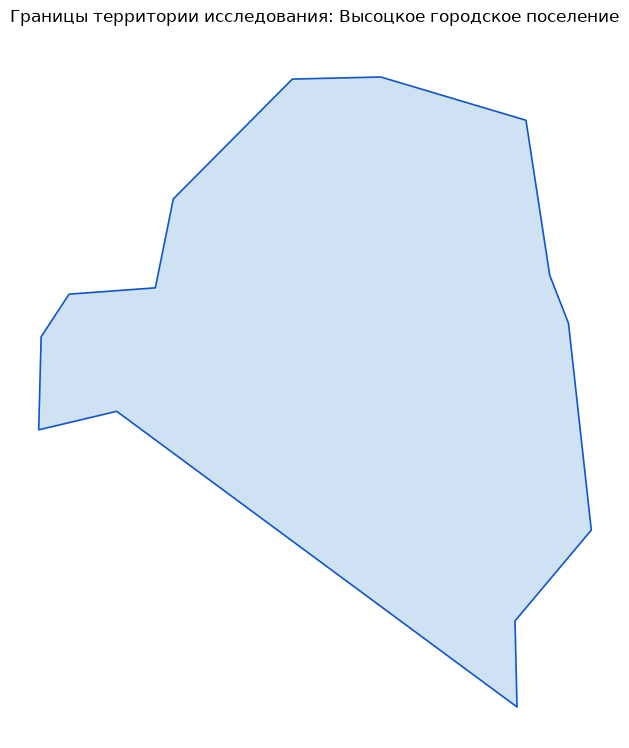

In [6]:
# Карта границ территории
ax = territory.plot(color="#cfe2f3", edgecolor="#1155cc", linewidth=1.2)
ax.set_title("Границы территории исследования: Высоцкое городское поселение")
ax.set_axis_off()
plt.show()

## 3. Исходные данные из OpenStreetMap

Наборы тегов взяты из учебного примера BlocksNet (`examples/pipeline.ipynb`).
Вода здесь важна: без неё акватория Финского залива превратилась бы в один огромный «квартал».

В последней ячейке раздела (3.4) из этих слоёв готовятся две вещи, которые исключаются из кварталов:
акватория (по линии берега) и полоса отвода железной дороги.

Скачивание идёт через публичные серверы Overpass API (данные OpenStreetMap). Территория поселения
большая (примерно 15 на 13 км), поэтому запросы выполняются долго, и сервер может оборвать
соединение — это обычное дело. Ноутбук сначала проверяет, какие зеркала отвечают, и скачивает
через работающие (несколько секунд на проверку), а скачанные слои сразу сохраняет в `data/raw/`,
поэтому повторный запуск берёт их с диска. Если не отвечает ни одно зеркало — смотрите раздел
«Если скачивание из OpenStreetMap не удалось» в конце ноутбука.

In [7]:
# 3.1. Наборы тегов OpenStreetMap (как в примере pipeline.ipynb библиотеки BlocksNet)
BC_TAGS = {
    "roads": {
        "highway": [
            "construction", "crossing", "living_street", "motorway", "motorway_link", "motorway_junction",
            "pedestrian", "primary", "primary_link", "raceway", "residential", "road", "secondary",
            "secondary_link", "services", "tertiary", "tertiary_link", "track", "trunk", "trunk_link",
            "turning_circle", "turning_loop", "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {
        "railway": "rail",
    },
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay", "wetland"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}
print("Готово. Наборов тегов:", len(BC_TAGS))

Готово. Наборов тегов: 3


In [8]:
if "territory" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 3.2. Скачивание слоёв. Сервер Overpass бывает перегружен, поэтому сначала проверяем, какие серверы
# отвечают, и начинаем с работающих, а если сервер обрывает соединение - переходим к следующему.
# Если объекта в OSM действительно нет - получаем пустой слой, и ноутбук не падает. Исключение -
# дороги и железные дороги: они основа нарезки кварталов, поэтому их пустой слой считается сбоем -
# иначе кварталы могут нарезаться вообще без улиц.
import requests


def split_overpass_servers(servers, timeout=15):
    "Проверяет серверы Overpass одним коротким запросом и возвращает (отвечающие, молчащие)."
    alive, dead = [], []
    for server in servers:
        host = server.split("/")[2]
        try:
            response = requests.get(server + "/status", timeout=timeout)
            if response.status_code == 200 and "Connected as" in response.text:
                print("   сервер", host, "- отвечает")
                alive.append(server)
            else:
                print("   сервер", host, "- ответ", response.status_code, "- пропускаю")
                dead.append(server)
        except Exception as error:
            print("   сервер", host, "- не отвечает (", type(error).__name__, ")")
            dead.append(server)
    return alive, dead


_SERVERS_CHECKED = False


def ensure_overpass_servers():
    "Проверяет серверы один раз - только когда действительно нужно что-то скачивать."
    global _SERVERS_CHECKED
    if _SERVERS_CHECKED:
        return
    _SERVERS_CHECKED = True
    print("Проверяю, какие серверы OpenStreetMap отвечают...")
    working_servers, silent_servers = split_overpass_servers(OVERPASS_SERVERS)
    # Работающие серверы - в начало списка, молчащие - в конец (вдруг ответят на большой запрос).
    OVERPASS_SERVERS[:] = working_servers + silent_servers
    if not working_servers:
        print("ВНИМАНИЕ: сейчас не отвечает ни один сервер. Всё равно пробую скачать -")
        print("         иногда сервер отвечает на данные, хотя на проверку не ответил.")


def download_osm(geometry, tags, name, required=False):
    "Скачивает объекты OSM внутри указанной геометрии, перебирая серверы Overpass и повторяя попытки."
    ensure_overpass_servers()
    polygon = gpd.GeoDataFrame(geometry=[geometry], crs=TARGET_CRS).to_crs("EPSG:4326").geometry.iloc[0]
    last_error = None

    for attempt in range(1, FETCH_ATTEMPTS + 1):
        for server in OVERPASS_SERVERS:
            host = server.split("/")[2]
            try:
                ox.settings.overpass_url = server
                layer = ox.features_from_polygon(polygon, tags=tags)
                if required and len(layer) == 0:
                    # Пустой ответ для обязательного слоя - это сбой сервера, а не отсутствие данных.
                    last_error = InsufficientResponseError("пустой ответ")
                    print("   сервер", host, "вернул пустой слой для", name, "- пробую другой")
                    continue
                print("   объектов (" + name + "):", len(layer), "| сервер:", host)
                return layer.reset_index(drop=True).to_crs(TARGET_CRS)
            except InsufficientResponseError:
                if required:
                    last_error = InsufficientResponseError("пустой ответ")
                    print("   сервер", host, "вернул пустой слой для", name, "- пробую другой")
                    continue
                print("   для", name, "в OSM ничего не найдено")
                return gpd.GeoDataFrame(geometry=[], crs=TARGET_CRS)
            except Exception as error:
                last_error = error
                print("   сервер", host, "не ответил (", type(error).__name__, ") - пробую другой")
        if attempt < FETCH_ATTEMPTS:
            print("   пауза", FETCH_PAUSE_S, "секунд и новая попытка...")
            time.sleep(FETCH_PAUSE_S)

    if required:
        raise RuntimeError(
            "Слой «" + name + "» скачался пустым. Так бывает, когда сервер не успевает обработать "
            "большой запрос (дороги - самый крупный слой). Подождите 5-10 минут и запустите ячейку "
            "заново: уже скачанные слои повторно не загружаются. Если это повторяется - увеличьте "
            "OVERPASS_TIMEOUT_S в ячейке 1.1 (например, до 600)."
        )

    raise RuntimeError(
        "Не удалось скачать слой «" + name + "»: серверы OpenStreetMap не отвечают. "
        "Подождите пару минут, проверьте интернет (иногда мешают VPN и антивирус) и запустите ячейку "
        "заново - уже скачанные слои сохранятся и повторно не загрузятся. "
        "Последняя ошибка: " + repr(last_error)
    )


def fetch_osm(tags, name, required=False):
    "Скачивает объекты OpenStreetMap по тегам внутри границ территории."
    return download_osm(territory.union_all(), tags, name, required=required)


def build_roads():
    # Дороги - основа нарезки кварталов: пустой слой означал бы, что кварталы нарезаны неправильно,
    # поэтому для этого слоя пустой ответ считается сбоем.
    layer = fetch_osm(BC_TAGS["roads"], "дороги", required=True)
    return layer[layer.geom_type.isin(["LineString", "MultiLineString"])].copy()


def build_railways():
    # Железная дорога тоже задаёт границы кварталов. Если на вашей территории её действительно нет,
    # замените ниже required=True на required=False.
    layer = fetch_osm(BC_TAGS["railways"], "железные дороги", required=True)
    return layer[layer.geom_type.isin(["LineString", "MultiLineString"])].copy()


def build_water():
    layer = fetch_osm(BC_TAGS["water"], "вода")
    return layer[layer.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].copy()


roads = cached(RAW_DIR / "roads.geojson", build_roads)
railways = cached(RAW_DIR / "railways.geojson", build_railways)
water = cached(RAW_DIR / "water.geojson", build_water)

[готовый файл] roads.geojson
[готовый файл] railways.geojson
[готовый файл] water.geojson


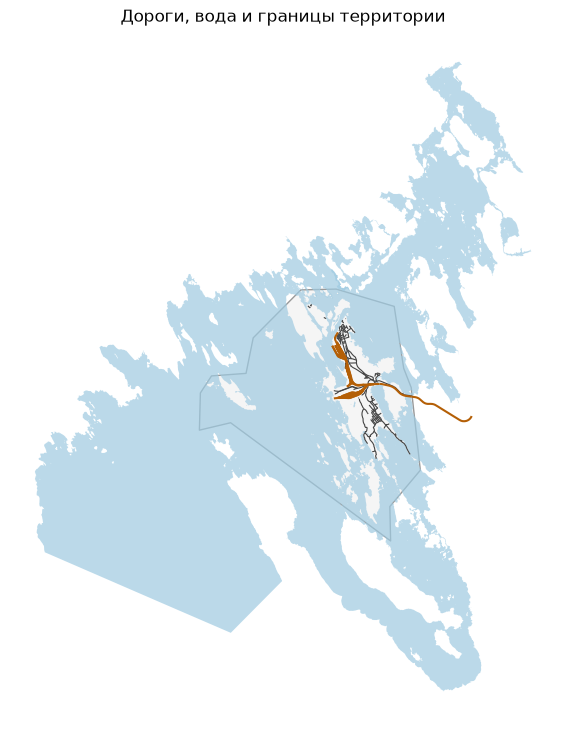

Дорог: 154 | участков железных дорог: 91 | объектов воды: 75


In [9]:
# 3.3. Карта исходных слоёв
ax = territory.plot(color="#f5f5f5", edgecolor="#999999")
if len(water) > 0:
    water.plot(ax=ax, color="#9ecae1", alpha=0.7)
if len(roads) > 0:
    roads.plot(ax=ax, color="#444444", linewidth=0.8)
if len(railways) > 0:
    railways.plot(ax=ax, color="#b45f06", linewidth=1.5)
ax.set_title("Дороги, вода и границы территории")
ax.set_axis_off()
plt.show()

print("Дорог:", len(roads), "| участков железных дорог:", len(railways), "| объектов воды:", len(water))

[готовый файл] coastline.geojson
   акватория внутри границ: 0.471 кв. км
   все пути объединены в одну полосу отвода шириной 40 м

Исключаем из кварталов:
   акватория:         0.471 кв. км
   полоса отвода жд:  121.5 га
   жд как барьеры:    0 участков


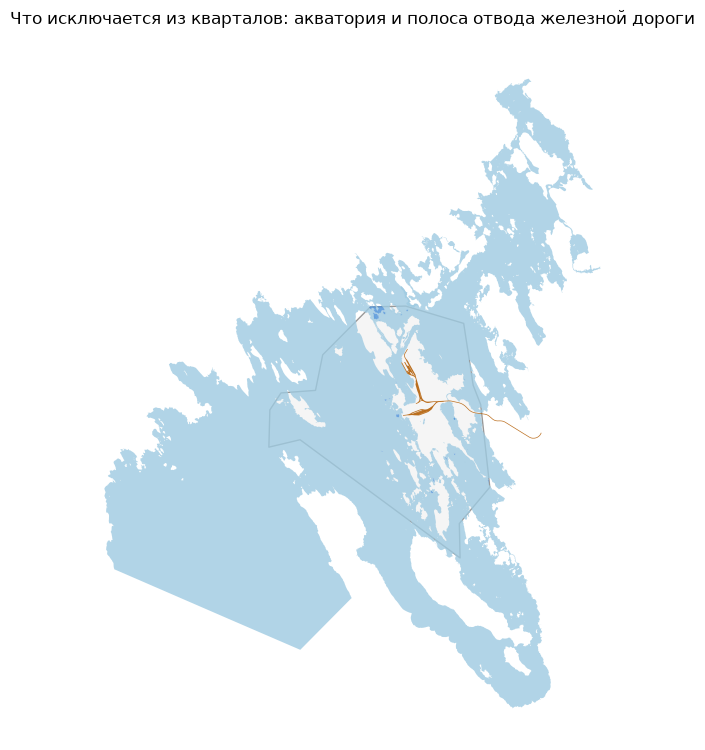

In [10]:
if "roads" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 3.4. Что исключаем из кварталов: акваторию (море) и полосу отвода железной дороги.
from shapely import union_all as union_geometries
from shapely.geometry import Point
from shapely.ops import polygonize

FRAME_M = 1500   # на сколько метров расширяем рамку, чтобы линия берега её точно пересекла


def territory_frame():
    "Прямоугольник вокруг территории: нужен, чтобы замкнуть линию берега."
    return territory.union_all().buffer(FRAME_M).envelope


def build_coastline():
    "Линия берега из OpenStreetMap (natural=coastline) - по ней определяется, где море."
    layer = download_osm(territory_frame(), {"natural": "coastline"}, "линия берега")
    layer = layer[layer.geom_type.isin(["LineString", "MultiLineString"])].copy()
    print("   линий берега:", len(layer))
    return layer


def left_side_points(coast, distance=300):
    "Точки слева от линии берега: в OpenStreetMap земля всегда слева от направления линии."
    coast_geometry = coast.union_all()
    lines = list(coast_geometry.geoms) if coast_geometry.geom_type == "MultiLineString" else [coast_geometry]
    points = []
    for line in lines:
        if line.length < 2 * distance:
            continue
        middle = line.interpolate(0.5, normalized=True)
        ahead = line.interpolate(0.51, normalized=True)
        dx, dy = ahead.x - middle.x, ahead.y - middle.y
        norm = (dx * dx + dy * dy) ** 0.5
        if norm == 0:
            continue
        points.append(Point(middle.x - dy / norm * distance, middle.y + dx / norm * distance))
    return points


def build_sea():
    "Море внутри границ поселения (в OSM море не нарисовано полигоном, только линией берега)."
    empty = gpd.GeoDataFrame(geometry=[], crs=TARGET_CRS)
    if not CLEAN_SEA:
        print("   исключение акватории отключено (CLEAN_SEA = False)")
        return empty
    if len(coastline) == 0:
        print("   линии берега нет - акваторию не исключаем")
        return empty

    frame = territory_frame()
    welded = union_geometries(list(coastline.geometry) + [frame.boundary])
    parts = [part for part in polygonize(welded) if part.area > 0]
    if len(parts) < 2:
        print("   линия берега не замкнулась в рамке - акваторию не исключаем (проверьте карту кварталов)")
        return empty

    points = left_side_points(coastline)
    is_land = [any(part.contains(point) for point in points) for part in parts]
    if not points or not any(is_land):
        print("   не удалось определить, где земля - акваторию не исключаем")
        return empty

    land = union_geometries([part for part, flag in zip(parts, is_land) if flag])
    water = union_geometries([part for part, flag in zip(parts, is_land) if not flag])

    # Проверка: в «земле» должно оказаться большинство дорог. Если нет - линия берега нарисована
    # в обратную сторону, и тогда землю и воду меняем местами.
    if len(roads) > 0:
        roads_geometry = roads.union_all()
        if roads_geometry.intersection(land).length < 0.5 * roads_geometry.length:
            print("   сторона берега определена неуверенно - меняю местами землю и воду")
            land, water = water, land

    if water.is_empty:
        print("   моря внутри границ не найдено")
        return empty

    sea = water.intersection(territory.union_all())
    if sea.is_empty:
        print("   моря внутри границ не найдено")
        return empty
    print("   акватория внутри границ:", round(sea.area / 1_000_000, 3), "кв. км")
    return gpd.GeoDataFrame(geometry=[sea], crs=TARGET_CRS)


def prepare_railways(layer):
    "Готовит железную дорогу к нарезке кварталов (режим задаётся в RAILWAY_MODE)."
    empty = gpd.GeoDataFrame(geometry=[], crs=TARGET_CRS)
    if len(layer) == 0 or RAILWAY_MODE == "all":
        if len(layer) > 0:
            print("   все пути используются как барьеры")
        return layer, empty

    if RAILWAY_MODE == "main_line":
        main = layer[layer.length >= MIN_RAILWAY_LENGTH_M]
        if len(main) == 0:
            main = layer.loc[[layer.length.idxmax()]]
            print("   длинных путей нет - оставляем один самый длинный участок")
        else:
            print("   оставлен только главный путь:", len(main), "из", len(layer), "участков")
        return main, empty

    # "corridor": объединяем все пути в одну полосу отвода, чтобы они не дробили территорию
    corridor = layer.buffer(RAILWAY_CORRIDOR_M).union_all().buffer(1)
    print("   все пути объединены в одну полосу отвода шириной", 2 * RAILWAY_CORRIDOR_M, "м")
    return empty, gpd.GeoDataFrame(geometry=[corridor], crs=TARGET_CRS)


coastline = cached(RAW_DIR / "coastline.geojson", build_coastline)
sea = build_sea()
rail_lines, rail_corridors = prepare_railways(railways)

print()
print("Исключаем из кварталов:")
print("   акватория:        ", round(sea.area.sum() / 1_000_000, 3), "кв. км")
print("   полоса отвода жд: ", round(rail_corridors.area.sum() / 10_000, 1), "га")
print("   жд как барьеры:   ", len(rail_lines), "участков")

ax = territory.plot(color="#f5f5f5", edgecolor="#999999")
if len(water) > 0:
    water.plot(ax=ax, color="#9ecae1", alpha=0.8)
if len(sea) > 0:
    sea.plot(ax=ax, color="#4a90d9", alpha=0.8)
if len(rail_corridors) > 0:
    rail_corridors.plot(ax=ax, color="#b45f06", alpha=0.9)
elif len(rail_lines) > 0:
    rail_lines.plot(ax=ax, color="#b45f06", linewidth=1.5)
ax.set_title("Что исключается из кварталов: акватория и полоса отвода железной дороги")
ax.set_axis_off()
plt.show()

## 4. Нарезка кварталов

Кварталы — это минимальные единицы анализа: территория режется улицами, а всё лишнее
(акватория, вода, полоса отвода железной дороги) из неё исключается.

Отдельно работает проверка на «осколки»: квартал меньше `MIN_BLOCK_AREA_M2` (по умолчанию
3000 кв. м) присоединяется к соседу с самой длинной общей границей, а если общей границы нет
(осколок касается соседа только углом) — к ближайшему кварталу. Именно из-за этого у железной
дороги не остаётся узких полосок между путями и отдельных «пылинок» в один квадратный метр.

In [11]:
if "roads" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 4.1. Нарезка кварталов.
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.postprocessing import postprocess_urban_blocks


def merge_small_blocks(layer, min_area_m2):
    "Присоединяет мелкие кварталы к соседу с самой длинной общей границей, а если её нет - к ближайшему."
    result = layer.copy()
    skipped = set()
    by_border, by_distance = 0, 0

    while True:
        areas = result.geometry.area
        too_small = areas[(areas < min_area_m2) & (~result.index.isin(skipped))]
        if too_small.empty:
            break

        index = too_small.idxmin()
        geometry = result.at[index, "geometry"]

        neighbour_id, shared_best = None, 0.0
        neighbours = result.iloc[result.sindex.query(geometry, predicate="intersects")]
        for neighbour, neighbour_geometry in neighbours.geometry.items():
            if neighbour == index:
                continue
            shared = neighbour_geometry.intersection(geometry).length
            if shared > shared_best:
                neighbour_id, shared_best = neighbour, shared

        if neighbour_id is None and len(neighbours) > 1:
            # Общей границы нет: после нарезки осколок часто касается соседа только углом.
            # Берём ближайший квартал - присоединённый осколок останется частью того же объекта.
            candidates = neighbours.geometry.drop(index, errors="ignore")
            if len(candidates) > 0:
                neighbour_id = candidates.distance(geometry).idxmin()
                by_distance += 1

        merged = None if neighbour_id is None else result.at[neighbour_id, "geometry"].union(geometry)
        if merged is None:
            skipped.add(index)          # соседей нет вообще - оставляем как есть
            continue
        if shared_best > 0:
            by_border += 1

        result.at[neighbour_id, "geometry"] = merged
        result = result.drop(index=index)

    result = result.reset_index(drop=True)[["geometry"]]
    print("   мелкие кварталы: присоединено по общей границе", by_border, "| по ближайшему соседу", by_distance)
    return gpd.GeoDataFrame(result, crs=layer.crs)


def build_blocks():
    "Режет территорию на кварталы: улицы - барьеры, вода, море и жд-полоса - исключения."
    layers = [layer[["geometry"]] for layer in [water, sea, rail_corridors] if len(layer) > 0]
    extra = (
        gpd.GeoDataFrame(pd.concat(layers, ignore_index=True), crs=TARGET_CRS)
        if layers
        else gpd.GeoDataFrame(geometry=[], crs=TARGET_CRS)
    )

    lines, polygons = preprocess_urban_objects(roads, rail_lines, extra)
    print("   линий-барьеров:", len(lines), "| полигонов-исключений:", len(polygons))

    layer = cut_urban_blocks(territory, lines, polygons)
    layer = postprocess_urban_blocks(layer)      # чиним самопересечения и осколки геометрии

    if MERGE_SMALL_BLOCKS:
        before = len(layer)
        layer = merge_small_blocks(layer, MIN_BLOCK_AREA_M2)
        print("   мелкие кварталы присоединены к соседям:", before, "->", len(layer))

    return layer


blocks = cached(RAW_DIR / "blocks.geojson", build_blocks)
print("Кварталов:", len(blocks))

[готовый файл] blocks.geojson
Кварталов: 255


Площадь кварталов, га:
count    255.00
mean      11.65
std       56.76
min        0.00
25%        0.02
50%        0.23
75%        1.98
max      611.77

Суммарная площадь кварталов, кв. км: 29.711
Площадь территории, кв. км:         121.547


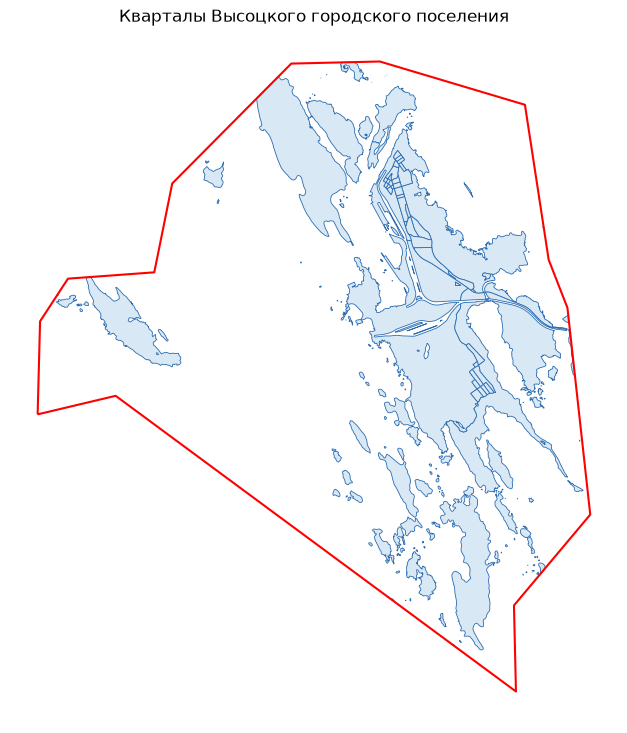

In [12]:
# 4.2. Сколько получилось кварталов и какого они размера
area_ha = blocks.area / 10_000

print("Площадь кварталов, га:")
print(area_ha.describe().round(2).to_string())
print()
print("Суммарная площадь кварталов, кв. км:", round(blocks.area.sum() / 1_000_000, 3))
print("Площадь территории, кв. км:        ", round(territory.area.sum() / 1_000_000, 3))

ax = blocks.plot(color="#d9e8f5", edgecolor="#2b6cb0", linewidth=0.6)
territory.boundary.plot(ax=ax, color="red", linewidth=1.5)
ax.set_title("Кварталы Высоцкого городского поселения")
ax.set_axis_off()
plt.show()

In [13]:
# 4.3. Интерактивная карта кварталов (можно двигать и приближать)
blocks_map = blocks.assign(area_ha=(blocks.area / 10_000).round(2)).explore(
    column="area_ha",
    cmap="Blues",
    legend=True,
    tiles="OpenStreetMap",
    name="Площадь квартала, га",
)
territory.copy().explore(m=blocks_map, color="red", style_kwds={"fillOpacity": 0}, name="Граница территории")
blocks_map

---
## 🛑 СТОП-ТОЧКА

**Кварталы готовы и сохранены в `data/raw/blocks.geojson`. Дальше ноутбук пока не запускайте.**

Здесь мы сверяем результат с реальностью и договариваемся о списке метрик. Посмотрите на карту
и на таблицу выше и обратите внимание на три вещи:

1. **Сколько кварталов получилось** — правдоподобно ли это число для поселения примерно
   15 на 13 км, бо́льшая часть которого — лес и прибрежные территории.
2. **Не попала ли в кварталы акватория** — море исключается автоматически по линии берега
   (раздел 3.4). Проверьте по карте: крупных кварталов без улиц вдоль берега быть не должно.
3. **Не осталось ли узких полосок вдоль железной дороги** — пути объединены в одну полосу
   отвода, а осколки меньше `MIN_BLOCK_AREA_M2` присоединены к соседям.

Ячейка ниже показывает короткую диагностику именно для этого разговора. Это ещё **не** расчёт
городских показателей, а проверка геометрии.

После разговора мы возвращаемся к разделам 5–9 (землепользование, здания, сервисы, время в пути,
показатели) и запускаем их по одной ячейке.

In [14]:
# 4.4. Диагностика перед расчётами (помогает решить на стоп-точке)
diagnostics = [
    ("Кварталов", len(blocks)),
    ("Медианная площадь квартала, га", round(float(area_ha.median()), 2)),
    ("Самый маленький квартал, га", round(float(area_ha.min()), 3)),
    ("Самый большой квартал, га", round(float(area_ha.max()), 2)),
    (f"Кварталов меньше {MIN_BLOCK_AREA_M2} кв. м", int((blocks.area < MIN_BLOCK_AREA_M2).sum())),
    ("Суммарная площадь кварталов, кв. км", round(blocks.area.sum() / 1_000_000, 3)),
    ("Площадь территории (вместе с морем), кв. км", round(territory.area.sum() / 1_000_000, 3)),
    ("Покрытие территории кварталами, %", round(100 * blocks.area.sum() / territory.area.sum(), 1)),
]

water_polygons = water[water.geom_type.isin(["Polygon", "MultiPolygon"])] if len(water) > 0 else water

if len(water_polygons) > 0:
    # Считаем только ту воду, что попала внутрь границ: в OSM один объект (например, залив)
    # может быть нарисован целиком и выходить далеко за пределы поселения.
    water_inside = water_polygons.intersection(territory.union_all())
    diagnostics.append(("Исключено: вода (озёра и реки), га", round(water_inside.area.sum() / 10_000, 1)))
if len(sea) > 0:
    diagnostics.append(("Исключено: акватория (море), кв. км", round(sea.area.sum() / 1_000_000, 3)))
if len(rail_corridors) > 0:
    diagnostics.append(("Исключено: полоса отвода жд, га", round(rail_corridors.area.sum() / 10_000, 1)))
elif len(rail_lines) > 0:
    diagnostics.append(("Железная дорога как барьеры, участков", len(rail_lines)))

# Кварталы не должны заходить на воду и на полосу отвода. Считаем площадь пересечения:
# касание границей (река как барьер) - это нормально, а вот пересечение по площади - ошибка.
excluded_layers = [layer for layer in [water_polygons, sea, rail_corridors] if len(layer) > 0]
if excluded_layers:
    excluded_geometry = union_geometries([layer.union_all() for layer in excluded_layers])
    overlap_area = blocks.geometry.intersection(excluded_geometry).area
    diagnostics.append(
        ("Кварталов, заходящих на воду или жд-полосу (должно быть 0)", int((overlap_area > 1).sum()))
    )

pd.DataFrame(diagnostics, columns=["Проверка", "Значение"]).to_string(index=False)

'                                                  Проверка  Значение\n                                                 Кварталов   255.000\n                            Медианная площадь квартала, га     0.230\n                               Самый маленький квартал, га     0.000\n                                 Самый большой квартал, га   611.770\n                               Кварталов меньше 3000 кв. м   134.000\n                       Суммарная площадь кварталов, кв. км    29.711\n               Площадь территории (вместе с морем), кв. км   121.547\n                         Покрытие территории кварталами, %    24.400\n                        Исключено: вода (озёра и реки), га  9048.300\n                       Исключено: акватория (море), кв. км     0.471\n                           Исключено: полоса отвода жд, га   121.500\nКварталов, заходящих на воду или жд-полосу (должно быть 0)     0.000'

## 5. Землепользование

Берём функциональные зоны из OpenStreetMap и правилами переводим их в типы землепользования
BlocksNet (жилое, деловое, рекреация, промышленное, транспорт, специальное, сельхоз).
Каждому кварталу достаётся тип, который занимает в нём наибольшую долю.

In [15]:
if "blocks" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

# Правила перевода зон OSM в типы землепользования (из примера pipeline.ipynb + значения для берега/порта)
LAND_USE_RULES = {
    "commercial": LandUse.BUSINESS,
    "retail": LandUse.BUSINESS,
    "residential": LandUse.RESIDENTIAL,
    "industrial": LandUse.INDUSTRIAL,
    "garages": LandUse.INDUSTRIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "quarry": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "construction": LandUse.SPECIAL,
    "religious": LandUse.SPECIAL,
    "military": LandUse.SPECIAL,
    "grass": LandUse.RECREATION,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "flowerbed": LandUse.RECREATION,
    "meadow": LandUse.RECREATION,
    "village_green": LandUse.RECREATION,
    "basin": LandUse.RECREATION,
    "piste": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "orchard": LandUse.AGRICULTURE,
    "allotments": LandUse.AGRICULTURE,
    "aquaculture": LandUse.AGRICULTURE,
    "greenhouse_horticulture": LandUse.AGRICULTURE,
    "plant_nursery": LandUse.AGRICULTURE,
    "landfill": LandUse.TRANSPORT,
    "railway": LandUse.TRANSPORT,
    "port": LandUse.TRANSPORT,
    "harbour": LandUse.TRANSPORT,
}


def build_functional_zones():
    "Функциональные зоны (землепользование) из OpenStreetMap."
    layer = fetch_osm({"landuse": True}, "функциональные зоны")
    if len(layer) == 0:
        return layer
    layer = layer.reset_index(drop=True)[["geometry", "landuse"]]
    layer = layer.rename(columns={"landuse": "functional_zone"})
    layer = layer[layer.geom_type.isin(["Polygon", "MultiPolygon"])]
    return layer


functional_zones = cached(RAW_DIR / "functional_zones.geojson", build_functional_zones)

if len(functional_zones) > 0:
    blocks = cached(
        RAW_DIR / "blocks_land_use.geojson",
        lambda: assign_land_use(blocks, functional_zones, LAND_USE_RULES),
    )
    land_use_labels = blocks["land_use"].map(lambda value: None if value is None else getattr(value, "value", value))
    print("Типы землепользования по кварталам:")
    print(land_use_labels.value_counts(dropna=False).to_string())
else:
    print("В OpenStreetMap нет данных о землепользовании - шаг пропускаем.")
    blocks = blocks.copy()
    blocks["land_use"] = None
    land_use_labels = pd.Series(index=blocks.index, dtype=object)

[готовый файл] functional_zones.geojson
[готовый файл] blocks_land_use.geojson
Типы землепользования по кварталам:
land_use
None           206
residential     22
agriculture     10
industrial       8
special          5
recreation       4


In [16]:
# 5.2. Карта землепользования
land_use_map = blocks.assign(land_use_label=land_use_labels).explore(
    column="land_use_label",
    categorical=True,
    legend=True,
    tiles="OpenStreetMap",
    name="Землепользование",
)
land_use_map

## 6. Здания

Скачиваем здания из OpenStreetMap. В OSM этажность и площади заполнены не всегда, поэтому
BlocksNet дозаполняет их по типовым правилам (`impute_buildings`), а затем агрегирует по кварталам:
получаем население, площадь застройки и общую площадь этажей на каждый квартал.

`LIVING_AREA_PER_PERSON = 30` — сколько квадратных метров жилой площади приходится на человека.

In [17]:
if "blocks" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 6.1. Скачивание зданий и подготовка признаков «жилое» и «этажность»
IS_LIVING_BUILDINGS = [
    "residential", "house", "apartments", "detached", "semidetached_house",
    "terrace", "dormitory", "bungalow",
]


def build_buildings():
    "Здания из OpenStreetMap с признаками «жилое» и «количество этажей»."
    layer = fetch_osm({"building": True}, "здания")
    if len(layer) == 0:
        return layer
    layer["is_living"] = layer["building"].isin(IS_LIVING_BUILDINGS)
    levels = layer["building:levels"] if "building:levels" in layer.columns else pd.Series(index=layer.index, dtype="float64")
    layer["number_of_floors"] = pd.to_numeric(levels, errors="coerce")
    return layer


buildings = cached(RAW_DIR / "buildings.geojson", build_buildings)

if len(buildings) > 0:
    buildings["is_living"] = buildings["is_living"].map(lambda value: str(value).strip().lower() in ("true", "1", "1.0"))
    buildings["number_of_floors"] = pd.to_numeric(buildings["number_of_floors"], errors="coerce")
    print("Зданий:", len(buildings))
    print("Из них жилых:", int(buildings["is_living"].sum()))
    print("С известной этажностью:", int(buildings["number_of_floors"].notna().sum()))

[готовый файл] buildings.geojson
Зданий: 1048
Из них жилых: 309
С известной этажностью: 135


In [18]:
# 6.2. Дозаполнение пропусков и агрегация зданий по кварталам
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.blocks.aggregation import aggregate_objects

if len(buildings) > 0:
    buildings_imputed = impute_buildings(buildings.copy(), default_living_demand=LIVING_AREA_PER_PERSON)
    buildings_blocks = cached(
        RESULT_DIR / "buildings_blocks.geojson",
        lambda: aggregate_objects(blocks, buildings_imputed)[0],
    )
    print("Население территории (оценка по зданиям OSM):", f"{buildings_blocks['population'].sum():,.0f}", "человек")
else:
    print("Зданий в OpenStreetMap нет - население и площади будут нулевыми.")
    buildings_blocks = blocks[["geometry"]].copy()
    for column in ["population", "footprint_area", "build_floor_area", "living_area", "non_living_area"]:
        buildings_blocks[column] = 0.0
    buildings_blocks["count"] = 0.0

2026-10-19 18:26:48.814 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-19 18:26:48.814 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-19 18:26:48.814 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-19 18:26:48.822 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-19 18:26:48.822 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


[готовый файл] buildings_blocks.geojson
Население территории (оценка по зданиям OSM): 1,403 человек


In [19]:
# 6.3. Интерактивная карта населения по кварталам
population_map = blocks[["geometry"]].join(buildings_blocks[["population"]]).explore(
    column="population",
    cmap="YlOrRd",
    legend=True,
    tiles="OpenStreetMap",
    name="Население квартала, человек",
)
population_map

## 7. Сервисы

Сначала показываем **полный список** всех типов сервисов BlocksNet (их 82) — это для протокола
исследования. Затем считаем только выбранные 12 сервисов из настроек (раздел 1.1).

Для каждого сервиса: скачиваем объекты из OpenStreetMap, дозаполняем ёмкость и агрегируем по
кварталам. Если какого-то сервиса на территории нет, он аккуратно пропускается.

In [20]:
if "pd" not in globals() or "SERVICES" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 7.1. Полный список всех типов сервисов BlocksNet с нормативами
from blocksnet.config import service_types_config

all_services = pd.DataFrame(
    [
        {
            "код": service,
            "название": service_types_config[service]["name_ru"],
            "норматив на 1000 жителей": service_types_config[service]["demand"],
            "радиус доступности, мин": service_types_config[service]["accessibility"],
        }
        for service in list(service_types_config)
    ]
)

print("Всего типов сервисов в BlocksNet:", len(all_services))
print("В расчёт включены:", ", ".join(SERVICES))
all_services

Всего типов сервисов в BlocksNet: 82
В расчёт включены: school, kindergarten, polyclinic, pharmacy, convenience, supermarket, playground, park, bus_stop, post, beach, pier


,код,название,норматив на 1000 жителей,"радиус доступности, мин"
0,school,школа,120,15
1,kindergarten,детский сад,61,7
2,hospital,больница,9,60
3,polyclinic,поликлиника,13,15
4,pitch,спортивная площадка,10,60
...,...,...,...,...
77,construction,объекты строительной промышленности,1,60
78,woodworking,объекты деревообрабатывающей и целлюлозно-бума...,1,60
79,electronics_industry,объекты электроники и высоких технологий,1,60
80,agricultural_services,объекты сельскохозяйственных сервисов,1,60


In [21]:
if "blocks" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 7.2. Скачивание и агрегация выбранных сервисов
SERVICE_TAGS = {
    "school": {"amenity": "school"},
    "kindergarten": {"amenity": "kindergarten"},
    "polyclinic": {"amenity": "clinic"},
    "pharmacy": {"amenity": "pharmacy"},
    "convenience": {"shop": "convenience"},
    "supermarket": {"shop": "supermarket"},
    "playground": {"leisure": "playground"},
    "park": {"leisure": "park"},
    "bus_stop": {"highway": "bus_stop"},
    "post": {"amenity": "post_office"},
    "beach": {"natural": "beach"},
    "pier": {"man_made": "pier"},
}


def ox_service_layer(service):
    "Сырой слой объектов сервиса из OpenStreetMap."

    def build():
        layer = fetch_osm(SERVICE_TAGS.get(service, {"amenity": service}), service)
        if len(layer) == 0:
            return layer
        if "capacity" not in layer.columns:
            layer["capacity"] = np.nan
        layer["capacity"] = pd.to_numeric(layer["capacity"], errors="coerce")
        return layer

    return cached(RAW_DIR / f"service_{service}.geojson", build)


service_blocks = {}
service_report = []

for service in SERVICES:
    try:
        raw = ox_service_layer(service)
        if len(raw) == 0:
            service_report.append({"сервис": service, "объектов в OSM": 0, "статус": "нет данных в OSM - пропущено"})
            continue
        layer = cached(
            RESULT_DIR / f"service_{service}_blocks.geojson",
            lambda raw=raw: aggregate_objects(blocks, impute_services(raw.copy(), service))[0],
        )
        service_blocks[service] = layer
        service_report.append(
            {
                "сервис": service,
                "объектов в OSM": len(raw),
                "статус": f"ёмкость по кварталам: {layer['capacity'].sum():.0f}",
            }
        )
    except Exception as error:
        service_report.append(
            {"сервис": service, "объектов в OSM": "-", "статус": f"пропущено: {type(error).__name__}"}
        )

print("Посчитаны данные по сервисам:", ", ".join(service_blocks) if service_blocks else "нет")

[готовый файл] service_school.geojson
[готовый файл] service_school_blocks.geojson
[готовый файл] service_kindergarten.geojson
[готовый файл] service_kindergarten_blocks.geojson
[считаю заново] service_polyclinic.geojson
Проверяю, какие серверы OpenStreetMap отвечают...
   сервер overpass-api.de - ответ 406 - пропускаю
   сервер overpass.private.coffee - ответ 429 - пропускаю
   сервер overpass.kumi.systems - ответ 429 - пропускаю
   сервер maps.mail.ru - ответ 504 - пропускаю
   сервер overpass.osm.jp - не отвечает ( SSLError )
ВНИМАНИЕ: сейчас не отвечает ни один сервер. Всё равно пробую скачать -
         иногда сервер отвечает на данные, хотя на проверку не ответил.
   для polyclinic в OSM ничего не найдено
   слой пустой - файл не создаём: service_polyclinic.geojson
[считаю заново] service_pharmacy.geojson
   для pharmacy в OSM ничего не найдено
   слой пустой - файл не создаём: service_pharmacy.geojson
[готовый файл] service_convenience.geojson
[готовый файл] service_convenience_

In [22]:
# 7.3. Отчёт по сервисам и карта ёмкости по кварталам
print("Отчёт по каждому сервису:")
print(pd.DataFrame(service_report).to_string(index=False))

main_service = next((s for s in SERVICES if s in service_blocks), None)
print()
print("Карта показывается для сервиса:", main_service)

if main_service is not None:
    service_blocks[main_service].explore(
        column="capacity",
        cmap="YlOrRd",
        legend=True,
        tiles="OpenStreetMap",
        name=f"Ёмкость сервиса: {main_service}",
    )

Отчёт по каждому сервису:
      сервис  объектов в OSM                       статус
      school               1    ёмкость по кварталам: 250
kindergarten               1     ёмкость по кварталам: 80
  polyclinic               0 нет данных в OSM - пропущено
    pharmacy               0 нет данных в OSM - пропущено
 convenience               1     ёмкость по кварталам: 50
 supermarket               1    ёмкость по кварталам: 200
  playground              12    ёмкость по кварталам: 240
        park               4   ёмкость по кварталам: 4800
    bus_stop               7    ёмкость по кварталам: 140
        post               1     ёмкость по кварталам: 60
       beach               9   ёмкость по кварталам: 3360
        pier              42    ёмкость по кварталам: 200

Карта показывается для сервиса: school


## 8. Граф улиц и время в пути между кварталами

**Источник графа:** OpenStreetMap (загрузка выполняется библиотекой **IduEdu**, которая входит
в состав BlocksNet). Граф скачивается готовым — мы его **не строим** сами и **не** делаем
интермодальный (общественный транспорт + пешком) граф.

**Режимы передвижения:**

- `walk` — пешеходный граф, скорость 5 км/ч;
- `drive` — автомобильный граф, скорость зависит от класса дороги.

**Единица измерения времени:** минуты. У каждого ребра графа есть признак `time_min`,
и матрица доступности тоже считается в минутах.

Матрица доступности — это таблица «квартал → квартал» с временем в пути между ними.
Оба графа и обе матрицы сохраняются в файлы и при повторном запуске берутся оттуда.

Если сервер OpenStreetMap не отвечает, ноутбук перебирает серверы из списка (как и при скачивании
слоёв) и повторяет попытку — отдельно настраивать ничего не нужно.

In [23]:
if "blocks" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 8.1. Скачивание готовых графов из OpenStreetMap и расчёт матриц времени в пути
import iduedu as ie
from blocksnet.relations.accessibility import get_accessibility_graph, calculate_accessibility_matrix

# IduEdu скачивает графы со своего сервера (по умолчанию lz4.overpass-api.de), которого нет в нашем
# списке. Поэтому перед скачиванием подставляем отвечающий сервер, а при ошибке перебираем остальные:
# иначе раздел останавливался бы на первом же перегруженном сервере.
ie.config.set_timeout(OVERPASS_TIMEOUT_S)


def download_graph(mode):
    "Скачивает граф, перебирая серверы Overpass и повторяя попытки."
    last_error = None
    for attempt in range(1, FETCH_ATTEMPTS + 1):
        for server in OVERPASS_SERVERS:
            host = server.split("/")[2]
            try:
                ie.config.set_overpass_url(server + "/interpreter")
                graph = get_accessibility_graph(territory, mode)
                print("   граф получен | сервер:", host)
                return graph
            except Exception as error:
                last_error = error
                print("   сервер", host, "не отдал граф (", type(error).__name__, ") - пробую другой")
        if attempt < FETCH_ATTEMPTS:
            print("   пауза", FETCH_PAUSE_S, "секунд и новая попытка...")
            time.sleep(FETCH_PAUSE_S)
    raise RuntimeError(
        "Не удалось скачать граф (" + mode + "). Последняя ошибка: " + type(last_error).__name__ + ". "
        "Подождите 5-10 минут и запустите ячейку заново: уже скачанные графы повторно не загружаются."
    )


graphs = {}
matrices = {}

for mode in GRAPH_MODES:
    name_ru = "пешеходный" if mode == "walk" else "автомобильный"
    speed_note = "5 км/ч" if mode == "walk" else "по классу дороги"
    print(f"--- {name_ru} граф ({mode}), {speed_note} ---")

    graph = cached_graph(DATA_DIR / f"graph_{mode}.pickle", lambda mode=mode: download_graph(mode))
    graphs[mode] = graph
    print("   узлов:", graph.number_of_nodes(), "| рёбер:", graph.number_of_edges(), "| CRS:", graph.graph.get("crs"))

    matrix = cached_table(
        DATA_DIR / f"accessibility_matrix_{mode}.parquet",
        lambda graph=graph: calculate_accessibility_matrix(blocks, graph),
    )
    matrices[mode] = matrix
    print("   матрица времени в пути:", matrix.shape[0], "x", matrix.shape[1], "значений (в минутах)")

--- пешеходный граф (walk), 5 км/ч ---
[готовый файл] graph_walk.pickle
   узлов: 607 | рёбер: 1644 | CRS: 32635
[готовый файл] accessibility_matrix_walk.parquet
   матрица времени в пути: 255 x 255 значений (в минутах)
--- автомобильный граф (drive), по классу дороги ---
[готовый файл] graph_drive.pickle
   узлов: 120 | рёбер: 304 | CRS: 32635
[готовый файл] accessibility_matrix_drive.parquet
   матрица времени в пути: 255 x 255 значений (в минутах)


In [24]:
# 8.2. Статистика времени в пути между кварталами (в минутах)
travel_rows = []
for mode, matrix in matrices.items():
    values = matrix.to_numpy(dtype="float64")
    reachable = values[np.isfinite(values)]
    travel_rows.append(
        {
            "режим": "пешком" if mode == "walk" else "на автомобиле",
            "пар квартал-квартал": int(matrix.size),
            "достижимо": int(reachable.size),
            "не достижимо": int((~np.isfinite(values)).sum()),
            "минимум, мин": round(float(reachable.min()), 1) if reachable.size else None,
            "медиана, мин": round(float(np.median(reachable)), 1) if reachable.size else None,
            "максимум, мин": round(float(reachable.max()), 1) if reachable.size else None,
        }
    )

travel_stats = pd.DataFrame(travel_rows)
travel_stats.to_csv(RESULT_DIR / "travel_time_stats.csv", index=False, encoding="utf-8-sig")
print("Время в пути показано в МИНУТАХ. Источник: OpenStreetMap (IduEdu).")
travel_stats

Время в пути показано в МИНУТАХ. Источник: OpenStreetMap (IduEdu).


,режим,пар квартал-квартал,достижимо,не достижимо,"минимум, мин","медиана, мин","максимум, мин"
0,пешком,65025,65025,0,0.0,93.3,233.6
1,на автомобиле,65025,65025,0,0.0,44.9,175.9


In [25]:
# 8.3. Карта: сколько минут идти от каждого квартала до центрального квартала
matrix = matrices[MAP_MODE]
center_point = territory.union_all().representative_point()
center_id = blocks.distance(center_point).idxmin()
travel_time = matrix[center_id].replace([np.inf, -np.inf], np.nan)

print("Режим передвижения:", "пешком" if MAP_MODE == "walk" else "на автомобиле")
print("Центральный квартал:", center_id, "| время в минутах от каждого квартала до него")
print(travel_time.describe().round(1).to_string())

blocks.assign(travel_time_min=travel_time.round(1)).explore(
    column="travel_time_min",
    cmap="RdYlGn_r",
    legend=True,
    tiles="OpenStreetMap",
    name="Время до центра, мин",
)

Режим передвижения: пешком
Центральный квартал: 77 | время в минутах от каждого квартала до него
count    255.0
mean      93.0
std       37.6
min        0.0
25%       78.7
50%       94.6
75%      124.7
max      152.2


c:\Users\harlekiro\python-package-boilerplate\.venv\Lib\site-packages\branca\colormap.py:124: RuntimeWarning: overflow encountered in scalar multiply
  float(self.vmin + (self.vmax - self.vmin) * k / 499.0) for k in range(500)


## 9. Городские показатели

Считаем показатели из учебного примера BlocksNet: плотностные характеристики застройки,
морфотипы по методикам Spacematrix и Strelka, доступность территории и обеспеченность сервисами.

In [26]:
if "buildings_blocks" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 9.1. Плотностные показатели застройки
from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks["site_area"] = buildings_blocks.area          # площадь квартала нужна для плотностей
density_df = cached_table(
    RESULT_DIR / "density_indicators.parquet",
    lambda: calculate_density_indicators(buildings_blocks),
)

print("Расшифровка:", "fsi - плотность застройки, gsi - доля застройки, mxi - доля жилья,")
print("             l - этажность, osr - обеспеченность открытыми пространствами")
density_df[["fsi", "gsi", "mxi", "l", "osr"]].describe().round(3)

[готовый файл] density_indicators.parquet
Расшифровка: fsi - плотность застройки, gsi - доля застройки, mxi - доля жилья,
             l - этажность, osr - обеспеченность открытыми пространствами


c:\Users\harlekiro\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\harlekiro\python-package-boilerplate\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,fsi,gsi,mxi,l,osr
count,255.000,255.000,44.000,44.000,255.000
mean,0.011,0.009,0.302,1.131,inf
std,0.045,0.032,0.317,0.494,NaN
min,0.000,0.000,0.000,1.000,1.732
25%,0.000,0.000,0.000,1.000,NaN
50%,0.000,0.000,0.210,1.000,NaN
75%,0.000,0.000,0.592,1.000,NaN
max,0.501,0.243,0.900,3.814,inf


In [27]:
# 9.2. Морфотипы Spacematrix (кластеризация кварталов по плотности и этажности)
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

# Кварталы без застройки получают нули, чтобы классификация не падала на пустых значениях
density_clean = density_df.copy()
for column in ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]:
    if column in density_clean.columns:
        density_clean[column] = density_clean[column].replace([np.inf, -np.inf], np.nan).fillna(0)

developed = int((density_clean["fsi"] > 0).sum())
n_clusters = max(2, min(11, developed))

if developed >= 2:
    print("Кварталов с застройкой:", developed, "| число морфотипов:", n_clusters)
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_clean, n_clusters=n_clusters)
    print()
    print("Морфотипы Spacematrix:")
    print(spacematrix_df["morphotype"].value_counts().to_string())

    # Центры кластеров (как в pipeline.ipynb, раздел 7.2.1) сохраняем отдельной таблицей:
    # по ней видно, чем один морфотип отличается от другого.
    spacematrix_clusters = spacematrix_clusters.rename_axis("cluster")
    counts = spacematrix_df["cluster"].dropna().astype(int).value_counts()
    spacematrix_clusters["кварталов"] = counts.reindex(spacematrix_clusters.index).fillna(0).astype(int)
    spacematrix_clusters.to_csv(RESULT_DIR / "spacematrix_clusters.csv", encoding="utf-8-sig")
    print("Сохранено: spacematrix_clusters.csv (центры кластеров)")
else:
    print("Кварталов с застройкой слишком мало для кластеризации - морфотипы Spacematrix пропускаем.")
    spacematrix_df = density_clean.assign(morphotype=None)
    spacematrix_clusters = pd.DataFrame()

Кварталов с застройкой: 44 | число морфотипов: 11

Морфотипы Spacematrix:
morphotype
low-rise low-density non-residential    22
low-rise low-density residential        15
low-rise low-density mixed-use           6
mid-rise low-density mixed-use           1
Сохранено: spacematrix_clusters.csv (центры кластеров)


In [28]:
# 9.3. Морфотипы Strelka (по этажности, плотности и доле жилья)
strelka_df = get_strelka_morphotypes(density_clean)
print("Морфотипы Strelka:")
print(strelka_df["morphotype"].value_counts(dropna=False).to_string())

blocks.join(spacematrix_df[["morphotype"]].rename(columns={"morphotype": "spacematrix"})).join(
    strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka"})
).explore(column="strelka", categorical=True, legend=True, tiles="OpenStreetMap", name="Морфотипы Strelka")

Морфотипы Strelka:
morphotype
NaN                         211
low-rise non-residential     20
individual residential       17
low-rise model                7


In [29]:
# 9.4. Доступность территории: средневзвешенное время до всех кварталов (в минутах)
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = {}
for mode, matrix in matrices.items():
    area_acc[mode] = area_accessibility(matrix, buildings_blocks)

print("Доступность территории по режимам передвижения (минуты):")
print(pd.concat({mode: layer["area_accessibility"].describe() for mode, layer in area_acc.items()}, axis=1).round(1).to_string())

area_acc_layer = {}
for mode, layer in area_acc.items():
    area_acc_layer[mode] = blocks[["geometry"]].join(layer)
    save_layer(area_acc_layer[mode], RESULT_DIR / f"area_accessibility_{mode}.geojson")

area_acc_layer[MAP_MODE].explore(
    column="area_accessibility",
    cmap="RdYlGn_r",
    legend=True,
    tiles="OpenStreetMap",
    name=f"Доступность территории, мин ({MAP_MODE})",
)

Доступность территории по режимам передвижения (минуты):
        walk  drive
count  255.0  255.0
mean    94.2   46.7
std     21.7   18.1
min     56.3   24.7
25%     77.4   31.1
50%     91.6   42.6
75%    110.1   60.2
max    165.0  110.3
   сохранено: area_accessibility_walk.geojson (255 объектов)
   сохранено: area_accessibility_drive.geojson (255 объектов)


In [30]:
# 9.5. Обеспеченность сервисами: какая доля спроса закрывается внутри радиуса доступности
from blocksnet.analysis.provision import competitive_provision, provision_strong_total, provision_weak_total

provision = {}
provision_report = []
provision_links = []

for service, layer in service_blocks.items():
    settings = service_types_config[service]
    table = blocks[["geometry"]].join(buildings_blocks[["population"]]).join(layer[["capacity"]])
    table["capacity"] = table["capacity"].fillna(0).astype(int)

    if table["population"].sum() <= 0:
        print("Для сервиса", service, "нет населения - пропускаем.")
        continue

    prov_df, links_df = competitive_provision(
        table,
        matrices[PROVISION_MODE],
        settings["accessibility"],
        settings["demand"],
    )
    provision[service] = prov_df
    provision_report.append(
        {
            "сервис": service,
            "название": settings["name_ru"],
            "граф": PROVISION_MODE,
            "радиус, мин": settings["accessibility"],
            "норматив на 1000 жителей": settings["demand"],
            "обеспеченность (сильная)": round(provision_strong_total(prov_df), 3),
            "обеспеченность (слабая)": round(provision_weak_total(prov_df), 3),
            "связей": int(len(links_df)),
        }
    )
    if len(links_df) > 0:
        # Кто кого обслуживает: source -> target и сколько единиц спроса закрыто.
        # В pipeline это links_df; сохраняем целиком, чтобы промежуточный результат не терялся.
        provision_links.append(links_df.reset_index().assign(сервис=service))

provision_df = pd.DataFrame(provision_report)
provision_df.to_csv(RESULT_DIR / "provision_report.csv", index=False, encoding="utf-8-sig")
if provision_links:
    pd.concat(provision_links, ignore_index=True).to_parquet(RESULT_DIR / "provision_links.parquet", index=False)

print("Обеспеченность считается по графу:", PROVISION_MODE, "(время в минутах)")
print("Сильная - с учётом конкуренции жителей за сервис, слабая - с сервисами и вне радиуса.")
print("Сохранено: provision_report.csv, provision_links.parquet")
provision_df

2026-10-19 18:28:00.548 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-19 18:28:00.565 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-19 18:28:00.603 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-19 18:28:00.619 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-19 18:28:01.647 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished
2026-10-19 18:28:01.680 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-19 18:28:01.683 | WARNING  | blocksnet.analysi

Обеспеченность считается по графу: walk (время в минутах)
Сильная - с учётом конкуренции жителей за сервис, слабая - с сервисами и вне радиуса.
Сохранено: provision_report.csv, provision_links.parquet


,сервис,название,граф,"радиус, мин",норматив на 1000 жителей,обеспеченность (сильная),обеспеченность (слабая),связей
0,school,школа,walk,15,120,0.486,0.486,18
1,kindergarten,детский сад,walk,7,61,0.081,0.081,3
2,convenience,магазин у дома,walk,10,200,0.171,0.171,2
3,supermarket,универсам/супермаркет/гипермаркет,walk,15,500,0.284,0.284,5
4,playground,детская площадка,walk,5,2,0.720,0.720,12
5,park,парк,walk,30,150,0.977,0.977,18
6,bus_stop,остановка общественного транспорта,walk,10,20,0.535,0.535,15
7,post,почта,walk,20,60,0.510,0.510,18
8,beach,пляж,walk,60,32,1.000,1.000,22
9,pier,пирс,walk,60,5,1.000,1.000,23


In [31]:
# 9.6. Карта обеспеченности и сохранение результата
provision_layer = None
if provision:
    provision_layer = blocks[["geometry"]].copy()
    for service, prov_df in provision.items():
        provision_layer[f"{service}_provision"] = prov_df["provision_strong"]
        provision_layer[f"{service}_provision_weak"] = prov_df["provision_weak"]
    save_layer(provision_layer, RESULT_DIR / "provision.geojson")

    map_service = next((s for s in SERVICES if s in provision), None)
    print("Карта обеспеченности для сервиса:", map_service)
    provision_layer.explore(
        column=f"{map_service}_provision",
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
        legend=True,
        tiles="OpenStreetMap",
        name=f"Обеспеченность: {map_service}",
    )
else:
    print("Обеспеченность не посчитана - нет подходящих данных.")

   сохранено: provision.geojson (255 объектов)
Карта обеспеченности для сервиса: school


## 10. Итоги

Собираем все показатели в один слой по кварталам и сохраняем его в GeoJSON.
Именно этот файл потом будет использоваться для HTML-отчёта с интерактивной картой и дашбордом.

In [32]:
if "density_df" not in globals():
    raise RuntimeError("Не выполнены ячейки выше. Запустите ноутбук сверху вниз (Run -> Run All Cells).")

# 10.1. Сводный слой по кварталам
study = blocks.copy()

buildings_columns = buildings_blocks[
    ["population", "footprint_area", "build_floor_area", "living_area", "non_living_area"]
].copy()
buildings_columns["buildings"] = buildings_blocks["count"]
study = study.join(buildings_columns)

# Все столбцы calculate_density_indicators (как в pipeline), включая share_living/share_non_living
study = study.join(density_df[["site_area", "fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]])

spacematrix_columns = spacematrix_df[["morphotype"]].rename(columns={"morphotype": "morphotype_spacematrix"})
if "cluster" in spacematrix_df.columns:
    spacematrix_columns["spacematrix_cluster"] = spacematrix_df["cluster"]
study = study.join(spacematrix_columns)
study = study.join(strelka_df[["morphotype"]].rename(columns={"morphotype": "morphotype_strelka"}))

for mode, layer in area_acc.items():
    study[f"area_accessibility_{mode}"] = layer["area_accessibility"]

for service, layer in service_blocks.items():
    study[f"{service}_capacity"] = layer["capacity"]

for service, prov_df in provision.items():
    study[f"{service}_provision"] = prov_df["provision_strong"]
    study[f"{service}_provision_weak"] = prov_df["provision_weak"]

study["land_use_label"] = land_use_labels
if "land_use" in study.columns:
    # в GeoJSON и CSV пишем понятные строки, а не служебные имена перечислений (LandUse.RESIDENTIAL)
    study["land_use"] = study["land_use"].map(
        lambda value: None if value is None else getattr(value, "value", value)
    )

save_layer(study, RESULT_DIR / "vysotsk_blocks_summary.geojson")
study.drop(columns="geometry").to_csv(RESULT_DIR / "vysotsk_blocks_summary.csv", index=False, encoding="utf-8-sig")

print("Кварталов в сводной таблице:", len(study))
print("Столбцов с показателями:", len(study.columns))
study.head(10)

c:\Users\harlekiro\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: NaN of Infinity value found. Skipped. Further messages of this type will be suppressed.
  ogr_write(


   сохранено: vysotsk_blocks_summary.geojson (255 объектов)
Кварталов в сводной таблице: 255
Столбцов с показателями: 60


,residential,business,recreation,industrial,transport,special,agriculture,land_use,share,geometry,population,footprint_area,build_floor_area,living_area,non_living_area,buildings,site_area,fsi,gsi,mxi,l,osr,share_living,share_non_living,morphotype_spacematrix,spacematrix_cluster,morphotype_strelka,area_accessibility_walk,area_accessibility_drive,school_capacity,kindergarten_capacity,convenience_capacity,supermarket_capacity,playground_capacity,park_capacity,bus_stop_capacity,post_capacity,beach_capacity,pier_capacity,school_provision,school_provision_weak,kindergarten_provision,kindergarten_provision_weak,convenience_provision,convenience_provision_weak,supermarket_provision,supermarket_provision_weak,playground_provision,playground_provision_weak,park_provision,park_provision_weak,bus_stop_provision,bus_stop_provision_weak,post_provision,post_provision_weak,beach_provision,beach_provision_weak,pier_provision,pier_provision_weak,land_use_label
0,0.788360,0.0,0.000000,0.000000,0.0,0.000000,0.0,residential,0.788360,"POLYGON ((585836.897 6721979.195, 585794.444 6...",2.0,370.904712,370.904712,104.318582,266.586130,7.0,5.391431e+03,0.068795,0.068795,0.281254,1.000000,13.535892,0.281254,0.718746,low-rise low-density mixed-use,8.0,individual residential,70.599455,25.647082,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,residential
1,0.074306,0.0,0.002366,0.084682,0.0,0.008935,0.0,industrial,0.084682,"POLYGON ((585878.494 6721843.553, 585892.197 6...",711.0,97243.106857,110956.188631,22932.335038,88023.853593,402.0,3.774884e+06,0.029393,0.025761,0.206679,1.141019,33.144979,0.235825,0.905194,low-rise low-density mixed-use,8.0,individual residential,65.745084,31.589654,0.0,0.0,0.0,0.0,60.0,1200.0,0.0,0.0,480.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,industrial
2,0.852644,0.0,0.000000,0.000000,0.0,0.000000,0.0,residential,0.852644,"POLYGON ((585745.358 6722029.568, 585782.839 6...",46.0,2630.806638,2630.806638,1454.152242,1176.654396,14.0,1.413270e+04,0.186150,0.186150,0.552740,1.000000,4.372002,0.552740,0.447260,low-rise low-density residential,4.0,low-rise model,70.978590,26.032174,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,residential
3,0.000000,0.0,0.004425,0.000000,0.0,0.000000,0.0,recreation,0.004425,"POLYGON ((589079.017 6719068.949, 589050.14 67...",0.0,2291.217678,2291.217678,0.000000,2291.217678,15.0,3.185966e+05,0.007192,0.007192,0.000000,1.000000,138.051223,0.000000,1.000000,low-rise low-density non-residential,2.0,low-rise non-residential,73.605276,38.513659,0.0,0.0,0.0,0.0,40.0,0.0,20.0,0.0,0.0,150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,recreation
4,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,None,NaN,"POLYGON ((588073.599 6719437.792, 588097.53 67...",0.0,0.000000,0.000000,0.000000,0.000000,0.0,1.123531e+05,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,NaN,NaN,86.161811,38.583287,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
5,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,None,NaN,"POLYGON ((587406.097 6719183.795, 587406.023 6...",0.0,0.000000,0.000000,0.000000,0.000000,0.0,5.664415e+01,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,NaN,NaN,56.333537,24.726228,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
6,0.397117,0.0,0.000000,0.000000,0.0,0.327757,0.0,residential,0.397117,"POLYGON ((585892.197 6721798.867, 585895.134 6...",22.0,1113.831064,1113.831064,729.350846,384.480217,14.0,1.315520e+04,0.084668,0.084668,0.654813,1.000000,10.810771,0.654813,0.345187,low-rise low-density residential,10.0,individual residential,68.865755,26.166956,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,

In [33]:
# 10.2. Короткие итоги в числах
print("=== Итоги исследования Высоцкого городского поселения ===")
print(f"Кварталов: {len(study)}")
print(f"Площадь территории: {territory.area.sum() / 1_000_000:.2f} кв. км")
print(f"Население (оценка по зданиям OSM): {buildings_blocks['population'].sum():,.0f} человек")
print(f"Жилых зданий: {int((buildings['is_living']).sum())}" if len(buildings) > 0 else "Зданий в OSM нет")
print()

for mode, matrix in matrices.items():
    values = matrix.to_numpy(dtype="float64")
    reachable = values[np.isfinite(values)]
    label = "пешком" if mode == "walk" else "на автомобиле"
    if reachable.size:
        print(f"Время между кварталами ({label}): медиана {float(np.median(reachable)):.1f} мин,",
              f"максимум {float(reachable.max()):.1f} мин")

print()
if len(provision_df) > 0:
    print("Обеспеченность сервисами по графу", PROVISION_MODE, "(доля спроса внутри радиуса доступности):")
    for _, row in provision_df.iterrows():
        print(f"  {row['сервис']:14s} {row['название']:32s} {row['обеспеченность (сильная)']}")
else:
    print("Обеспеченность не посчитана.")

=== Итоги исследования Высоцкого городского поселения ===
Кварталов: 255
Площадь территории: 121.55 кв. км
Население (оценка по зданиям OSM): 1,403 человек
Жилых зданий: 309

Время между кварталами (пешком): медиана 93.3 мин, максимум 233.6 мин
Время между кварталами (на автомобиле): медиана 44.9 мин, максимум 175.9 мин

Обеспеченность сервисами по графу walk (доля спроса внутри радиуса доступности):
  school         школа                            0.486
  kindergarten   детский сад                      0.081
  convenience    магазин у дома                   0.171
  supermarket    универсам/супермаркет/гипермаркет 0.284
  playground     детская площадка                 0.72
  park           парк                             0.977
  bus_stop       остановка общественного транспорта 0.535
  post           почта                            0.51
  beach          пляж                             1.0
  pier           пирс                             1.0


### Сверка с учебным примером `pipeline.ipynb`

| Шаг `pipeline.ipynb` | Где в этом ноутбуке | Где в дашборде |
|---|---|---|
| 1.1–1.3. Границы, вода, дороги, железные дороги, нарезка кварталов | 3.1–3.4 | слой «Граница поселения», кварталы |
| 2. Назначение землепользования | 5.1–5.3 | слой «Землепользование», таблица |
| 3. Граф и матрица доступности | 8.1–8.2 (walk и drive вместо intermodal — по заданию) | раздел «Транспортная доступность» |
| 4. Здания: `is_living`, этажность, дозаполнение, агрегация | 6.1–6.2 | население на карте, график, таблица |
| 5. Сервисы: дозаполнение и агрегация | 7.2 | точки услуг, таблица услуг |
| 6. Итоговая таблица | 10.1 | раздел «Все показатели по кварталам» |
| 7.1. `competitive_provision`: `provision_strong`, `provision_weak`, `links_df` | 9.5–9.6 | таблица услуг, слой обеспеченности, `provision_links.parquet` |
| 7.2. `calculate_density_indicators` | 9.1 | FSI и GSI на карте, полная таблица |
| 7.2.1. Spacematrix: морфотипы и центры кластеров | 9.2 | слой и график морфотипов, таблица кластеров |
| 7.2.2. Strelka | 9.3 | слой и график Strelka |
| 7.3. `area_accessibility` | 9.4 | слои доступности, раздел 2 |

Отличия от учебного примера сделаны осознанно: вместо интермодального графа считаются два
отдельных (пешком и на автомобиле), вместо одного примера со школой — 12 значимых для посёлка
сервисов, а границы берутся по OSM relation, а не по названию населённого пункта.

### О чём говорят эти числа

- **Население** — это оценка по зданиям из OpenStreetMap, а не официальная статистика: она зависит
  от того, насколько полно в OSM указаны этажность и границы зданий.
- **Время в пути** сравнивается между двумя режимами: если пешком и на машине медиана близка,
  значит город компактный и автомобиль почти не даёт выигрыша.
- **Морфотипы** показывают, из каких типов застройки состоит город: малоэтажная индивидуальная,
  среднеэтажная, микрорайонная и т.д.
- **Обеспеченность** — доля потребности, которую жители закрывают в пределах радиуса доступности
  (например, 15 минут для школы). Значения ниже 1 означают дефицит: либо сервисов мало, либо они
  далеко. Обратите внимание: в расчёт попадают только объекты внутри границ поселения.

## Что где сохраняется

```
examples/vysotsk/
  vysotsk_study.ipynb                    <- этот ноутбук
  data/
    version.txt             версия исходных данных (см. раздел «Повторный запуск»)
    osm_cache/      кэш ответов серверов OpenStreetMap (можно удалять в любой момент)
    raw/            сырые слои OSM и производные геометрии
      boundary.geojson, roads.geojson, railways.geojson, water.geojson, coastline.geojson
      functional_zones.geojson, buildings.geojson
      service_<код>.geojson
      blocks.geojson            <- кварталы (результат стоп-точки)
      blocks_land_use.geojson
    graph_walk.pickle, graph_drive.pickle                          <- графы улиц
    accessibility_matrix_walk.parquet, accessibility_matrix_drive.parquet  <- время в минутах
    results/
      buildings_blocks.geojson, service_<код>_blocks.geojson
      density_indicators.parquet, area_accessibility_walk.geojson, area_accessibility_drive.geojson
      provision.geojson, provision_report.csv
      provision_links.parquet          <- кто кого обслуживает (links_df из pipeline)
      spacematrix_clusters.csv         <- центры кластеров морфотипов
      travel_time_stats.csv
      vysotsk_blocks_summary.geojson   <- главный итог: все показатели по кварталам
      vysotsk_blocks_summary.csv       <- то же в виде таблицы для Excel
```

## Повторный запуск

1. Открыть ноутбук заново (команда запуска — в самом начале).
2. Запустить все ячейки сверху вниз. При `FORCE_RECOMPUTE = False` ноутбук **не** будет
   скачивать и считать заново то, что уже лежит в папке `data/`: он напишет «[готовый файл]»
   и сразу перейдёт к следующему шагу. Это быстро и не требует интернета.
3. Если нужно пересчитать всё с нуля (например, изменились настройки):
   - либо поставить `FORCE_RECOMPUTE = True` в ячейке 1.1 и запустить всё заново;
   - либо удалить нужный файл из папки `data/` — ноутбук пересчитает только его.
4. Если расчёт прервался (например, пропал интернет) — просто запустите ячейки снова:
   всё, что успело сохраниться, будет переиспользовано.
5. Ячейки, которые скачивают данные из OpenStreetMap, требуют интернета. Если интернет
   недоступен, а файлы в `data/` уже есть — всё равно всё посчитается.

### Если скачивание из OpenStreetMap не удалось

Данные скачиваются с публичных серверов Overpass API (Overpass перегружен почти всегда — это
нормально). Ноутбук устроен так, чтобы перегрузка сервера не портила результат:

- перед скачиванием он **сам проверяет, какие зеркала отвечают, и начинает с работающих**
  (список задан в `OVERPASS_SERVERS` в ячейке 1.1);
- если сервер не ответил, ноутбук переходит к следующему, а весь список проходит до
  `FETCH_ATTEMPTS` раз с паузой `FETCH_PAUSE_S` секунд;
- ответы серверов дополнительно кэшируются в `data/osm_cache`, поэтому повторный запуск быстрее;
- **если не ответил ни один сервер, ячейка останавливается с понятным красным сообщением**, а не
  подставляет пустой слой. Это важно: раньше обрыв связи мог тихо превратиться в «дорог нет» и
  испортить нарезку кварталов, теперь такого не произойдёт;
- то же самое, если пустым вернулся слой **дорог или железных дорог**: для этих двух слоёв сбой
  сервера и правда отсутствие данных различить нельзя, а нарезка кварталов без дорог бессмысленна,
  поэтому ноутбук останавливается, а не считает дальше. Как быть: подождать 5–10 минут и запустить
  ячейку заново; если повторяется — увеличить `OVERPASS_TIMEOUT_S` в ячейке 1.1 (по умолчанию 300
  секунд): дороги — самый большой слой, и серверу может не хватать времени.

Что делать по шагам:

1. Подождать 5–10 минут и запустить ячейку заново — у Overpass бывают часы пик.
2. Проверить интернет, отключить VPN и антивирусную проверку HTTPS (они часто рвут соединение).
3. Если не помогает — добавить в `OVERPASS_SERVERS` (ячейка 1.1) другой сервер. Кроме уже
   включённых в список, это могут быть `https://overpass.osm.ch/api` и другие экземпляры из
   списка на странице https://wiki.openstreetmap.org/wiki/Overpass_API (раздел
   «Public Overpass API instances»). Новый адрес должен заканчиваться на `/api`.

### Если поменяли границы территории или настройки подготовки данных

Старые файлы в `data/` посчитаны для прежней территории, поэтому их нельзя переиспользовать.
Для этого в ячейке 1.2 есть константа `DATA_VERSION`. Увеличьте её (например, `"2"` -> `"3"`) и
запустите ноутбук заново: при запуске старые файлы расчёта будут удалены автоматически, и всё
посчитается для новой территории. В текущей версии ноутбука `DATA_VERSION = "2"` — как раз потому,
что границы были заменены на Высоцкое городское поселение.